# Notebook 05 — Definición de KPIs (Fase 4)

**Qué hace este notebook:** define los indicadores que mirará la gerencia, los calcula con los datos limpios y los conecta con las hipótesis. Es el puente entre el análisis estadístico y el dashboard: **cada KPI de aquí se programa como medida DAX en Power BI** (archivo `dashboard/medidas_dax.md`) y debe dar **el mismo número**.

**Criterio para elegir un KPI:** (1) responde una decisión concreta, (2) se calcula sin ambigüedad desde el modelo de datos, (3) se relaciona con al menos una hipótesis o pregunta clave.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
df = pd.read_parquet(PROC / 'lineas_limpias.parquet')
rfm = pd.read_parquet(PROC / 'rfm_clientes.parquet')
ventas = df[df['tipo'] == 'Venta']
devol = df[df['tipo'] == 'Devolucion']

def tasa_recompra_90d(v):
    """% de clientes (observables 90 dias) que hacen un 2o pedido dentro de 90 dias de su 1o."""
    p = (v.dropna(subset=['cliente_id']).groupby(['cliente_id', 'factura'])['fecha'].min().reset_index()
         .sort_values(['cliente_id', 'fecha', 'factura']))
    p['n'] = p.groupby('cliente_id').cumcount()
    p1 = p[p['n'] == 0].set_index('cliente_id')['fecha']
    p2 = p[p['n'] == 1].set_index('cliente_id')['fecha']
    obs = p1[p1 <= ventas['fecha'].max() - pd.Timedelta(days=90)]
    return ((p2.reindex(obs.index) - obs).dt.days <= 90).mean()

def kpis(v, d):
    bruta = v['importe'].sum()
    dev = -d['importe'].sum()
    pedidos = v['factura'].nunique()
    cli = v.dropna(subset=['cliente_id'])
    por_cliente = cli.groupby('cliente_id')['importe'].sum().sort_values(ascending=False)
    k20 = max(1, int(round(len(por_cliente) * .2)))
    return {
        'ventas_brutas': bruta, 'devoluciones': dev, 'ingresos_netos': bruta - dev,
        'pedidos': pedidos, 'ticket_promedio': bruta / pedidos,
        'tasa_devolucion': dev / bruta,
        'clientes_activos': cli['cliente_id'].nunique(),
        'tasa_recompra_90d': tasa_recompra_90d(v),
        'concentracion_top20': por_cliente.head(k20).sum() / por_cliente.sum(),
    }

total = kpis(ventas, devol)
pd.Series(total, name='total (dic-2009 a dic-2011)').to_frame()

,total (dic-2009 a dic-2011)
ventas_brutas,"19,399,949.84"
devoluciones,"470,842.33"
ingresos_netos,"18,929,107.51"
pedidos,"39,514.00"
ticket_promedio,490.96
tasa_devolucion,0.02
clientes_activos,"5,852.00"
tasa_recompra_90d,0.47
concentracion_top20,0.77


## 1. Los 7 KPIs

| # | KPI | Fórmula | Justificación de negocio | Hipótesis / pregunta |
|---|---|---|---|---|
| **K1** | **Ingresos netos** | Ventas brutas − devoluciones | Es la línea de ingresos real; descuenta lo que el cliente devolvió | H1 · P1 |
| **K2** | **Ticket promedio** | Ventas brutas ÷ nº de pedidos | Mide cuánto vale cada pedido; guía la estrategia comercial por mercado | H2 · P5 |
| **K3** | **Tasa de devolución** | Valor devuelto ÷ ventas brutas | Cuantifica la pérdida por cancelaciones; alerta de problemas de producto o logística | H3 · P4 |
| **K4** | **Clientes activos** | Clientes identificados distintos con ≥ 1 pedido | Tamaño de la base que genera ingresos; denominador de casi todo lo demás | P2, P3 |
| **K5** | **Tasa de recompra a 90 días** | % de clientes que hacen un 2.º pedido ≤ 90 días tras el 1.º | Mide retención temprana; es más barato retener que captar | H4, H5, H6 · P3 |
| **K6** | **Concentración del ingreso (top 20 % de clientes)** | Ventas del 20 % de clientes que más compran ÷ ventas de clientes identificados | Riesgo de dependencia: perder pocos clientes grandes duele mucho | P2 |
| **K7** | **Crecimiento interanual (ene–nov)** | Ingresos netos ene–nov 2011 ÷ ene–nov 2010 − 1 | Dice si el negocio crece; se compara el mismo periodo para no sesgar por el mes incompleto | H1 · P1 |

In [3]:
# K7: crecimiento interanual comparable (ene-nov de cada anio)
def netos_periodo(anio):
    m = (df['anio'] == anio) & (df['mes'] <= 11)
    return df.loc[m, 'importe'].sum()
k7 = netos_periodo(2011) / netos_periodo(2010) - 1

# KPIs por mercado y por anio comparable
por_mercado = {g: kpis(ventas[ventas['pais_grupo'] == g], devol[devol['pais_grupo'] == g])
               for g in ['Reino Unido', 'Exterior']}
tabla = pd.DataFrame({'Total': total, **por_mercado})
tabla.loc['crecimiento_interanual'] = [k7, np.nan, np.nan]

fmt = {'ventas_brutas': '£{:,.0f}', 'devoluciones': '£{:,.0f}', 'ingresos_netos': '£{:,.0f}', 'pedidos': '{:,.0f}',
       'ticket_promedio': '£{:,.0f}', 'tasa_devolucion': '{:.2%}', 'clientes_activos': '{:,.0f}',
       'tasa_recompra_90d': '{:.1%}', 'concentracion_top20': '{:.1%}', 'crecimiento_interanual': '{:+.1%}'}
mostrar = tabla.copy().astype(object)
for k, f in fmt.items():
    mostrar.loc[k] = [f.format(x) if pd.notna(x) else '-' for x in tabla.loc[k]]
mostrar

,Total,Reino Unido,Exterior
ventas_brutas,"£19,399,950","£16,557,108","£2,842,842"
devoluciones,"£470,842","£386,493","£84,349"
ingresos_netos,"£18,929,108","£16,170,614","£2,758,493"
pedidos,"39,514","36,182","3,332"
ticket_promedio,£491,£458,£853
tasa_devolucion,2.43%,2.33%,2.97%
clientes_activos,"5,852","5,334",518
tasa_recompra_90d,46.7%,46.8%,46.2%
concentracion_top20,76.9%,75.5%,82.7%
crecimiento_interanual,+2.3%,-,-


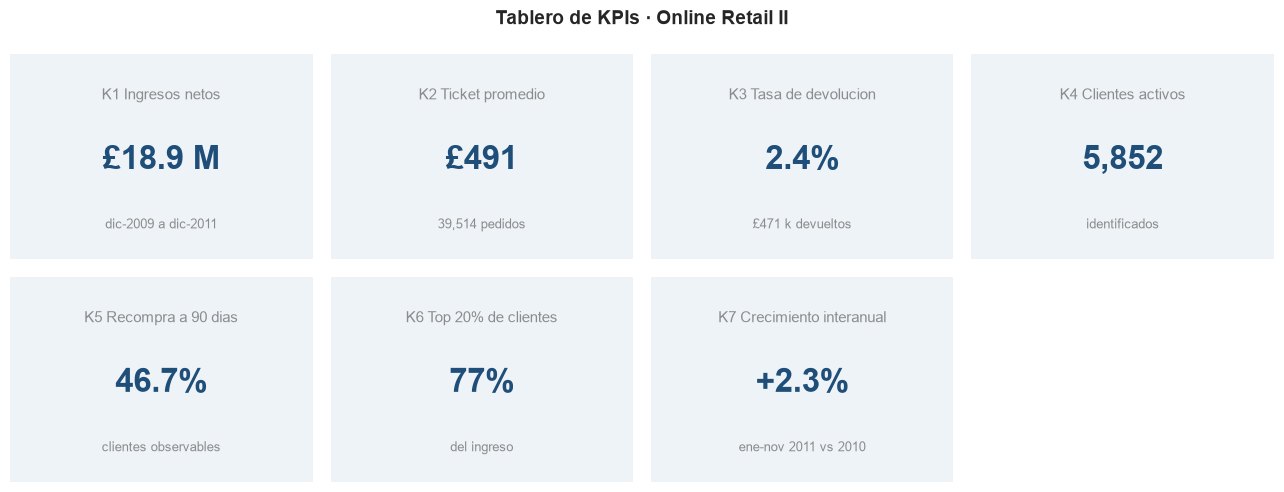

In [4]:
# Tablero de KPIs (para el README y las diapositivas)
tarjetas = [
    ('K1 Ingresos netos', f'£{total["ingresos_netos"]/1e6:,.1f} M', 'dic-2009 a dic-2011'),
    ('K2 Ticket promedio', f'£{total["ticket_promedio"]:,.0f}', f'{total["pedidos"]:,} pedidos'),
    ('K3 Tasa de devolucion', f'{total["tasa_devolucion"]:.1%}', f'£{total["devoluciones"]/1e3:,.0f} k devueltos'),
    ('K4 Clientes activos', f'{total["clientes_activos"]:,}', 'identificados'),
    ('K5 Recompra a 90 dias', f'{total["tasa_recompra_90d"]:.1%}', 'clientes observables'),
    ('K6 Top 20% de clientes', f'{total["concentracion_top20"]:.0%}', 'del ingreso'),
    ('K7 Crecimiento interanual', f'{k7:+.1%}', 'ene-nov 2011 vs 2010'),
]
fig, axs = plt.subplots(2, 4, figsize=(13, 5))
for ax, t in zip(axs.flat, tarjetas + [None]):
    ax.axis('off')
    if t is None:
        continue
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color='#EEF3F8', zorder=0))
    ax.text(.5, .78, t[0], ha='center', fontsize=11, color=GRIS, transform=ax.transAxes)
    ax.text(.5, .44, t[1], ha='center', fontsize=24, fontweight='bold', color=AZUL, transform=ax.transAxes)
    ax.text(.5, .15, t[2], ha='center', fontsize=9, color=GRIS, transform=ax.transAxes)
plt.suptitle('Tablero de KPIs · Online Retail II', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(FIG / '05_tablero_kpis.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Interpretación de cada KPI

Las frases se generan **con los mismos números de la tabla**, para que el texto nunca se desfase de los datos si se vuelve a ejecutar.

In [5]:
ru, ex = por_mercado['Reino Unido'], por_mercado['Exterior']
interpretaciones = pd.DataFrame([
    ('K1', f'£{total["ingresos_netos"]/1e6:,.2f} M netos en dos anios. Las devoluciones restan £{total["devoluciones"]/1e3:,.0f} k de £{total["ventas_brutas"]/1e6:,.2f} M brutos.'),
    ('K2', f'Cada pedido vale en promedio £{total["ticket_promedio"]:,.0f} (la mediana es mucho menor, £{ventas.groupby("factura")["importe"].sum().median():,.0f}: pocos pedidos grandes jalan el promedio). '
           f'El Exterior (£{ex["ticket_promedio"]:,.0f}) supera al Reino Unido (£{ru["ticket_promedio"]:,.0f}), coherente con H2.'),
    ('K3', f'Solo {total["tasa_devolucion"]:.1%} del valor vendido se devuelve: el problema de devoluciones es pequeno en dinero. '
           f'El Exterior devuelve {ex["tasa_devolucion"]:.1%} vs {ru["tasa_devolucion"]:.1%} en el Reino Unido.'),
    ('K4', f'{total["clientes_activos"]:,} clientes identificados generaron las ventas; los invitados (sin ID) no se pueden seguir en el tiempo.'),
    ('K5', f'{total["tasa_recompra_90d"]:.1%} de los clientes compra de nuevo en 90 dias: casi uno de cada dos. '
           f'No hay diferencia relevante entre Reino Unido ({ru["tasa_recompra_90d"]:.1%}) y Exterior ({ex["tasa_recompra_90d"]:.1%}), coherente con H6.'),
    ('K6', f'El 20% de los clientes aporta {total["concentracion_top20"]:.0%} del ingreso: alta dependencia de una base pequena de clientes grandes.'),
    ('K7', f'Los ingresos netos de ene-nov 2011 cambiaron {k7:+.1%} frente a ene-nov 2010: el negocio esta {"creciendo" if k7 > .02 else "estable" if k7 > -.02 else "contrayendose"}.'),
], columns=['KPI', 'Interpretacion'])
pd.set_option('display.max_colwidth', 400)
interpretaciones

,KPI,Interpretacion
0,K1,£18.93 M netos en dos anios. Las devoluciones restan £471 k de £19.40 M brutos.
1,K2,"Cada pedido vale en promedio £491 (la mediana es mucho menor, £301: pocos pedidos grandes jalan el promedio). El Exterior (£853) supera al Reino Unido (£458), coherente con H2."
2,K3,Solo 2.4% del valor vendido se devuelve: el problema de devoluciones es pequeno en dinero. El Exterior devuelve 3.0% vs 2.3% en el Reino Unido.
3,K4,"5,852 clientes identificados generaron las ventas; los invitados (sin ID) no se pueden seguir en el tiempo."
4,K5,"46.7% de los clientes compra de nuevo en 90 dias: casi uno de cada dos. No hay diferencia relevante entre Reino Unido (46.8%) y Exterior (46.2%), coherente con H6."
5,K6,El 20% de los clientes aporta 77% del ingreso: alta dependencia de una base pequena de clientes grandes.
6,K7,Los ingresos netos de ene-nov 2011 cambiaron +2.3% frente a ene-nov 2010: el negocio esta creciendo.


In [6]:
# Valores de referencia para validar el dashboard (las medidas DAX deben dar estos numeros)
ref = tabla['Total'].rename('valor').to_frame()
ref.loc['crecimiento_interanual', 'valor'] = k7
ref.to_csv(PROC / 'kpis_referencia.csv')

# KPIs por segmento RFM (para la pagina de clientes del dashboard)
seg = (rfm.groupby('segmento').agg(clientes=('cliente_id', 'size'), ingreso=('monetario', 'sum'),
                                   recencia_mediana=('recencia', 'median'), frecuencia_mediana=('frecuencia', 'median'))
       .assign(pct_clientes=lambda d: d['clientes'] / d['clientes'].sum(), pct_ingreso=lambda d: d['ingreso'] / d['ingreso'].sum())
       .sort_values('ingreso', ascending=False))
seg.style.format({'ingreso': '£{:,.0f}', 'pct_clientes': '{:.1%}', 'pct_ingreso': '{:.1%}'})

,clientes,ingreso,recencia_mediana,frecuencia_mediana,pct_clientes,pct_ingreso
segmento,,,,,,
Campeones,1190,"£12,379,123",17.000000,13.000000,20.3%,73.6%
En riesgo,1446,"£2,770,438",185.000000,4.000000,24.7%,16.5%
Recientes,1260,"£1,055,625",24.000000,3.000000,21.5%,6.3%
Dormidos,1956,"£617,729",402.000000,1.000000,33.4%,3.7%


**Qué cuenta el tablero de KPIs:**
- El negocio generó **£18,9 M netos** con 39.514 pedidos de **£491** en promedio; las devoluciones son solo el **2,4 %** del valor.
- **K7 (+2,3 % interanual)** muestra un negocio **estable, casi sin crecimiento**: 2010 y 2011 facturan casi lo mismo. El motor para crecer no es vender más a los mismos, sino **retener y reactivar** (K5 y segmentos RFM).
- **K6 (77 %)** advierte dependencia de pocos clientes; en el Exterior es aún mayor (83 %), porque pocos mayoristas concentran las ventas de exportación.
- **K5 (46,7 %)** dice que casi la mitad de los clientes nuevos no vuelve en 90 días: ahí está la oportunidad.

**Cada KPI se replica en Power BI** con una medida DAX (archivo `dashboard/medidas_dax.md`); los valores de `data/processed/kpis_referencia.csv` sirven para **validar** que el dashboard calcula lo mismo que el notebook.